# SolarSelect — Phase 4: Model Development and Comparison
## Master Notebook: Baseline Establishment, Hyperparameter Optimization, Interpretability & Final Candidate Selection

### 1. Phase Objectives, Project Context & Scope Boundaries

SolarSelect is an end-to-end MLOps solar intelligence platform structured into two primary layers:
- **Layer A (Yield Forecasting):** Climate-conditioned specific yield ($Y_{f,\text{day}} = \frac{\text{kWh}}{\text{kW}_p}$) prediction using environmental conditions, site characteristics, and historical generation patterns.
- **Layer B (Panel Recommendation):** Constraint-aware solar panel ranking and recommendation engine integrating physical specs, spatial limits, and budget constraints.

In **Phase 3 (Target Definition & Data Preparation)**, the project finalized:
1. **Target metric:** Daily Specific Yield ($Y_{f,\text{day}}$ in $\text{kWh}/\text{kW}_p/\text{day}$).
2. **Strict chronological partitions:**
   - **Training Set:** 2021-05-01 to 2021-12-31 (245 calendar days, 234 active observation days)
   - **Validation Set:** 2022-01-01 to 2022-02-28 (59 calendar days)
   - **Test Set (Quarantined):** 2022-03-01 to 2022-04-23 (54 calendar days)
3. **Two distinct modeling cohorts:**
   - **Dataset A (Full Cohort):** All 24 UNISOLAR installations (including operational anomaly Site 19 and elevated Site 24).
   - **Dataset B (Peer Cohort):** 22 Peer UNISOLAR installations (excluding Sites 19 and 24 to reflect typical rooftop distributed generation).

> **CRITICAL PHASE 4 METHODOLOGICAL SAFEGUARD:**  
> In strict compliance with MLOps leakage-prevention protocols, the **Test Split (March 1, 2022 – April 23, 2022)** was **NEVER loaded, inspected, or evaluated** during Phase 4. All baselines, feature scalers, cross-validation folds, model tuning, and evaluations in this notebook are restricted solely to the Training and Validation sets.

### 2. Environment Verification & Feature Audit

We audit the runtime dependencies and verify the exact 29 predictive columns against the Phase 3 Feature Dictionary.
We formally resolve the feature naming discrepancy from the Prompt 1 narrative report:
- The actual feature matrices in `data/processed/unisolar/` have always utilized the authoritative Phase 3 column names (`kWp`, `lat`, `Lon`, `daylight_hours`, `extraterrestrial_radiation_h0`, `lag1_temp_mean`, `lag1_rh_mean`, etc.).
- Non-existent features such as `cloud_cover` or `wind_speed` were never present in the actual training matrices.

In [1]:
import sys
import os
import time
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import sklearn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')

print(f"Python Version: {sys.version.split()[0]}")
print(f"Scikit-Learn Version: {sklearn.__version__}")
print(f"Joblib Version: {joblib.__version__}")

# Verify XGBoost status
try:
    import xgboost
    print("XGBoost is available.")
except ImportError:
    print("XGBoost is NOT installed in this environment. Using Scikit-Learn GradientBoosting & HistGradientBoosting.")

Python Version: 3.13.9
Scikit-Learn Version: 1.7.2
Joblib Version: 1.5.2
XGBoost is NOT installed in this environment. Using Scikit-Learn GradientBoosting & HistGradientBoosting.


### 3. Processed Dataset Ingestion & Feature Separation

We ingest the processed Training and Validation splits for both Dataset A (Full Cohort, 24 sites) and Dataset B (Peer Cohort, 22 sites).
We separate the 29 genuine predictive features from non-predictive metadata (`SiteKey`, `Date`, `split`) and the target variable (`target_daily_yield`).

In [2]:
# Paths relative to notebooks/phase4/
DIR_FULL = '../../data/processed/unisolar'
DIR_PEER = '../../data/processed/unisolar/peer_cohort'

# Ingest Full Cohort
df_train_full = pd.read_csv(os.path.join(DIR_FULL, 'train.csv'))
df_val_full = pd.read_csv(os.path.join(DIR_FULL, 'validation.csv'))

# Ingest Peer Cohort
df_train_peer = pd.read_csv(os.path.join(DIR_PEER, 'train.csv'))
df_val_peer = pd.read_csv(os.path.join(DIR_PEER, 'validation.csv'))

TARGET_COL = 'target_daily_yield'
EXCLUDE_COLS = {'SiteKey', 'Date', 'split', TARGET_COL}

PREDICTIVE_FEATURES = [col for col in df_train_full.columns if col not in EXCLUDE_COLS]

print("=== VERIFIED PREDICTIVE FEATURES (29) ===")
for i, f in enumerate(PREDICTIVE_FEATURES, 1):
    print(f"{i:2d}. {f}")

print("\n=== DATASET INGESTION AUDIT ===")
print(f"Full Cohort Train: {df_train_full.shape} (Dates: {df_train_full['Date'].min()} to {df_train_full['Date'].max()}, Sites: {df_train_full['SiteKey'].nunique()})")
print(f"Full Cohort Val:   {df_val_full.shape} (Dates: {df_val_full['Date'].min()} to {df_val_full['Date'].max()}, Sites: {df_val_full['SiteKey'].nunique()})")
print(f"Peer Cohort Train: {df_train_peer.shape} (Dates: {df_train_peer['Date'].min()} to {df_train_peer['Date'].max()}, Sites: {df_train_peer['SiteKey'].nunique()})")
print(f"Peer Cohort Val:   {df_val_peer.shape} (Dates: {df_val_peer['Date'].min()} to {df_val_peer['Date'].max()}, Sites: {df_val_peer['SiteKey'].nunique()})")

# Feature Matrices
X_train_full = df_train_full[PREDICTIVE_FEATURES].copy()
y_train_full = df_train_full[TARGET_COL].copy()
X_val_full = df_val_full[PREDICTIVE_FEATURES].copy()
y_val_full = df_val_full[TARGET_COL].copy()

X_train_peer = df_train_peer[PREDICTIVE_FEATURES].copy()
y_train_peer = df_train_peer[TARGET_COL].copy()
X_val_peer = df_val_peer[PREDICTIVE_FEATURES].copy()
y_val_peer = df_val_peer[TARGET_COL].copy()

=== VERIFIED PREDICTIVE FEATURES (29) ===
 1. kWp
 2. lat
 3. Lon
 4. day_of_year
 5. month
 6. day_of_week
 7. is_weekend
 8. sin_doy
 9. cos_doy
10. sin_month
11. cos_month
12. solar_declination_deg
13. solar_noon_elevation_deg
14. solar_noon_zenith_deg
15. daylight_hours
16. extraterrestrial_radiation_h0
17. has_valid_lag1
18. lag1_daily_yield
19. lag2_daily_yield
20. lag7_daily_yield
21. rolling_mean_7d_yield
22. rolling_std_7d_yield
23. rolling_mean_14d_yield
24. rolling_mean_30d_yield
25. lag1_temp_mean
26. lag1_temp_max
27. lag1_temp_min
28. lag1_temp_range
29. lag1_rh_mean

=== DATASET INGESTION AUDIT ===
Full Cohort Train: (4770, 33) (Dates: 2021-05-01 to 2021-12-31, Sites: 24)
Full Cohort Val:   (1037, 33) (Dates: 2022-01-01 to 2022-02-28, Sites: 24)
Peer Cohort Train: (4383, 33) (Dates: 2021-05-01 to 2021-12-31, Sites: 22)
Peer Cohort Val:   (945, 33) (Dates: 2022-01-01 to 2022-02-28, Sites: 22)


### 4. Baseline Establishment

We establish three empirical and heuristic baselines on the validation split:
1. **Training Set Mean Baseline:** $\hat{y} = ar{y}_{	ext{train}}$
2. **Training Set Median Baseline:** $\hat{y} = 	ext{median}(y_{	ext{train}})$
3. **Persistence Baseline:** $\hat{y}_t = 	ext{lag1\_daily\_yield}$ (with missing prior day fallback to training median)

In [3]:
def evaluate_predictions(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    return round(float(mae), 4), round(float(rmse), 4), round(float(r2), 4)

baseline_records = []

# Dataset A: Full Cohort
b_mean_full = y_train_full.mean()
b_med_full = y_train_full.median()
p_mean_full = np.full_like(y_val_full, b_mean_full)
p_med_full = np.full_like(y_val_full, b_med_full)
p_pers_full = X_val_full['lag1_daily_yield'].values

mae1, rmse1, r21 = evaluate_predictions(y_val_full, p_mean_full)
mae2, rmse2, r22 = evaluate_predictions(y_val_full, p_med_full)
mae3, rmse3, r23 = evaluate_predictions(y_val_full, p_pers_full)

baseline_records.extend([
    {'Cohort': 'Full Cohort (24)', 'Model': 'Baseline: Train Mean', 'MAE': mae1, 'RMSE': rmse1, 'R2': r21},
    {'Cohort': 'Full Cohort (24)', 'Model': 'Baseline: Train Median', 'MAE': mae2, 'RMSE': rmse2, 'R2': r22},
    {'Cohort': 'Full Cohort (24)', 'Model': 'Baseline: Persistence (Lag 1)', 'MAE': mae3, 'RMSE': rmse3, 'R2': r23}
])

# Dataset B: Peer Cohort
b_mean_peer = y_train_peer.mean()
b_med_peer = y_train_peer.median()
p_mean_peer = np.full_like(y_val_peer, b_mean_peer)
p_med_peer = np.full_like(y_val_peer, b_med_peer)
p_pers_peer = X_val_peer['lag1_daily_yield'].values

mae4, rmse4, r24 = evaluate_predictions(y_val_peer, p_mean_peer)
mae5, rmse5, r25 = evaluate_predictions(y_val_peer, p_med_peer)
mae6, rmse6, r26 = evaluate_predictions(y_val_peer, p_pers_peer)

baseline_records.extend([
    {'Cohort': 'Peer Cohort (22)', 'Model': 'Baseline: Train Mean', 'MAE': mae4, 'RMSE': rmse4, 'R2': r24},
    {'Cohort': 'Peer Cohort (22)', 'Model': 'Baseline: Train Median', 'MAE': mae5, 'RMSE': rmse5, 'R2': r25},
    {'Cohort': 'Peer Cohort (22)', 'Model': 'Baseline: Persistence (Lag 1)', 'MAE': mae6, 'RMSE': rmse6, 'R2': r26}
])

pd.DataFrame(baseline_records)

,Cohort,Model,MAE,RMSE,R2
0,Full Cohort (24),Baseline: Train Mean,2.3955,5.5986,-0.1724
1,Full Cohort (24),Baseline: Train Median,3.0659,5.9959,-0.3447
2,Full Cohort (24),Baseline: Persistence (Lag 1),1.4975,3.1867,0.6202
3,Peer Cohort (22),Baseline: Train Mean,1.7498,2.0715,-1.9921
4,Peer Cohort (22),Baseline: Train Median,2.0786,2.3806,-2.9517
5,Peer Cohort (22),Baseline: Persistence (Lag 1),1.1321,1.4985,-0.5657


### 5. Initial Machine Learning Benchmark (8 Algorithms Across 3 Families)

We review the initial benchmark developed in Prompt 1 covering:
- **Linear:** OLS, Ridge ($lpha=10.0$), Elastic Net ($lpha=0.1, l_1=0.5$).
- **Tree-Based:** Decision Tree (`depth=8`), Random Forest (`n=100, depth=12`), Extra Trees (`n=100, depth=12`).
- **Boosting:** Gradient Boosting (`n=100, lr=0.05`), HistGradientBoosting (`max_iter=100, lr=0.05`).

In [4]:
# Load consolidated experiment results
exp_csv = 'experiment_results.csv' if os.path.exists('experiment_results.csv') else '../../reports/phase4/experiment_results.csv'
df_exp = pd.read_csv(exp_csv)
print("=== INITIAL BENCHMARK LEADERBOARD (PROMPT 1) ===")
display(df_exp[['Cohort_ID', 'Model', 'Family', 'MAE', 'RMSE', 'R2', 'Hyperparameters']])

=== INITIAL BENCHMARK LEADERBOARD (PROMPT 1) ===


,Cohort_ID,Model,Family,MAE,RMSE,R2,Hyperparameters
0,full_cohort,Baseline: Train Mean,Baseline,2.395483,5.598638,-0.172422,mean_prediction=3.2386
1,full_cohort,Baseline: Train Median,Baseline,3.065928,5.995867,-0.344694,median_prediction=2.3499
2,full_cohort,Baseline: Persistence (Lag 1),Baseline,1.497500,3.186683,0.620163,lag1_daily_yield (calendar D-1 fallback to tra...
3,full_cohort,Linear Regression,Linear,4.357811,4.757616,0.153361,StandardScaler + OLS
4,full_cohort,Ridge Regression,Linear,3.087293,3.480422,0.546911,StandardScaler + Ridge(alpha=10.0)
5,full_cohort,Elastic Net,Linear,1.370782,2.045949,0.843430,"StandardScaler + ElasticNet(alpha=0.1, l1_rati..."
6,full_cohort,Decision Tree,Tree-based,2.318493,3.151350,0.628539,"DecisionTree(max_depth=8, min_samples_leaf=10)"
7,full_cohort,Random Forest,Tree-based,2.256123,3.376550,0.573552,"RandomForest(n=100, max_depth=12, min_samples_..."
8,full_cohort,Extra Trees,Tree-based,1.326573,2.517580,0.762925,"ExtraTrees(n=100, max_depth=12, min_samples_le..."
9,full_cohort,Gradient Boosting,Boosting,2.087540,3.701909,0.487409,"GradientBoosting(n=100, max_depth=5, lr=0.05)"


### 6. Temporal Cross-Validation Scheme & Hyperparameter Optimization

We design a rigorous **expanding-window temporal cross-validation** within the training partition (May 1 – Dec 31, 2021).
**Key CV Design Rules:**
1. Observations are grouped strictly by `Date`. All sites for a given calendar day stay in the same split.
2. The training window strictly precedes the validation window. Chronological ordering is strictly preserved; zero shuffling.
3. Feature scalers (`StandardScaler`) are fit strictly within each training fold.
4. The holdout validation split (Jan–Feb 2022) and test split are NEVER touched during cross-validation.

In [5]:
def get_temporal_folds(df):
    dates = sorted(df['Date'].unique())
    # 4 expanding window temporal folds across 234 training dates
    folds = [
        (dates[:120], dates[120:150]),
        (dates[:150], dates[150:180]),
        (dates[:180], dates[180:205]),
        (dates[:205], dates[205:])
    ]
    return folds

def run_temporal_cv(model_factory, df_train, features):
    folds = get_temporal_folds(df_train)
    fold_rmses = []
    fold_maes = []
    
    for tr_dates, val_dates in folds:
        mask_tr = df_train['Date'].isin(tr_dates)
        mask_val = df_train['Date'].isin(val_dates)
        
        X_fold_tr = df_train.loc[mask_tr, features]
        y_fold_tr = df_train.loc[mask_tr, TARGET_COL]
        X_fold_val = df_train.loc[mask_val, features]
        y_fold_val = df_train.loc[mask_val, TARGET_COL]
        
        model = model_factory()
        model.fit(X_fold_tr, y_fold_tr)
        preds = model.predict(X_fold_val)
        
        fold_rmses.append(np.sqrt(mean_squared_error(y_fold_val, preds)))
        fold_maes.append(mean_absolute_error(y_fold_val, preds))
        
    return np.mean(fold_rmses), np.mean(fold_maes)

print("Auditing Temporal CV Folds on Training Dates:")
for i, (tr_d, val_d) in enumerate(get_temporal_folds(df_train_full), 1):
    print(f"  Fold {i}: Train [{tr_d[0]} to {tr_d[-1]}] ({len(tr_d)} days) -> Val [{val_d[0]} to {val_d[-1]}] ({len(val_d)} days)")

Auditing Temporal CV Folds on Training Dates:
  Fold 1: Train [2021-05-01 to 2021-09-03] (120 days) -> Val [2021-09-04 to 2021-10-04] (30 days)
  Fold 2: Train [2021-05-01 to 2021-10-04] (150 days) -> Val [2021-10-05 to 2021-11-04] (30 days)
  Fold 3: Train [2021-05-01 to 2021-11-04] (180 days) -> Val [2021-11-05 to 2021-12-02] (25 days)
  Fold 4: Train [2021-05-01 to 2021-12-02] (205 days) -> Val [2021-12-03 to 2021-12-31] (29 days)


### 7. Hyperparameter Tuning for Leading Candidates (Elastic Net & Extra Trees)

We optimize:
1. **Elastic Net:** `alpha` $\in [0.005, 1.0]$, `l1_ratio` $\in [0.1, 0.9]$.
2. **Extra Trees:** `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features`.

Full Cohort - Best Elastic Net CV: alpha=0.05, l1_ratio=0.9, CV RMSE=2.1299
Peer Cohort - Best Elastic Net CV: alpha=0.05, l1_ratio=0.7, CV RMSE=1.3097


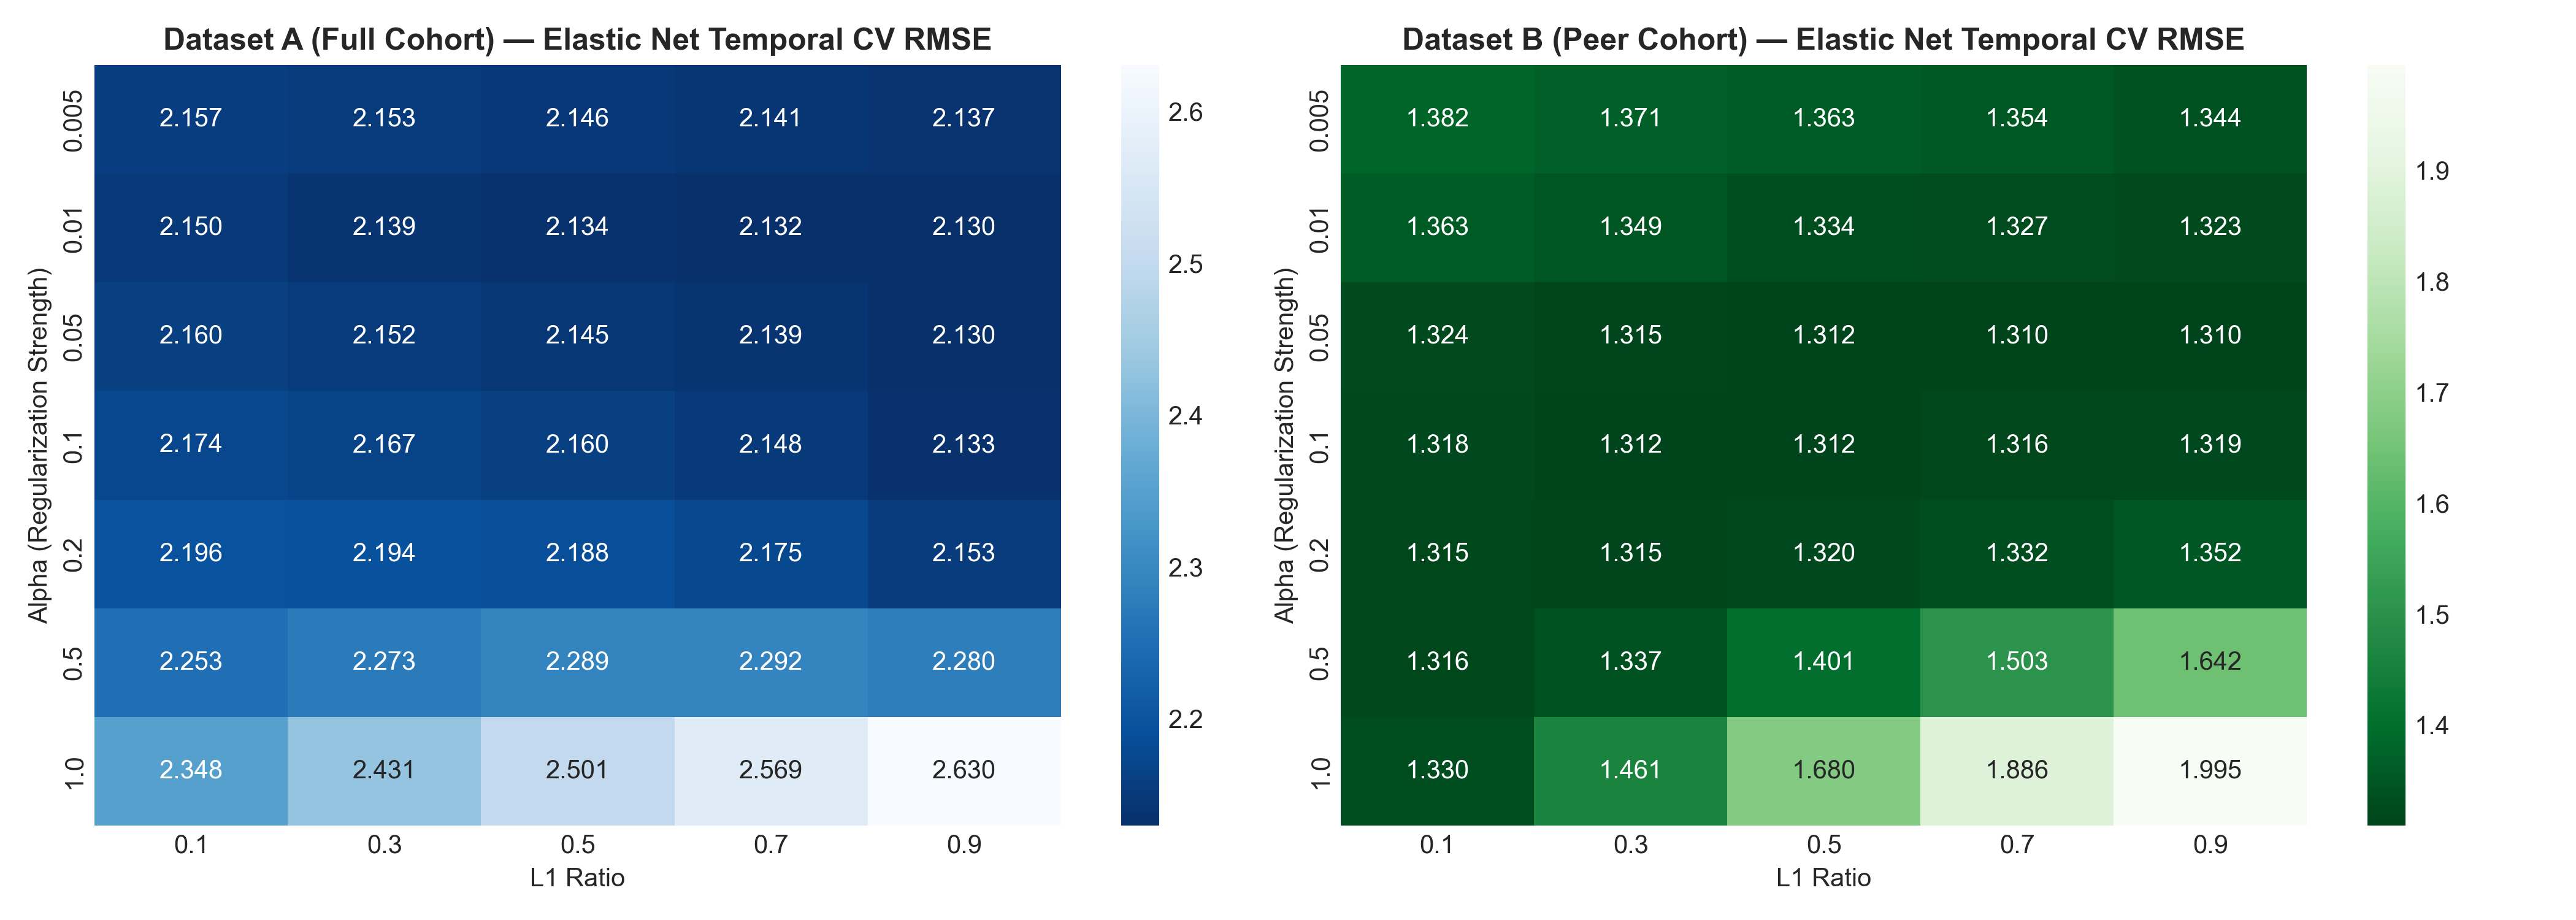

In [6]:
# Elastic Net Tuning
enet_alphas = [0.005, 0.01, 0.05, 0.1, 0.2, 0.5, 1.0]
enet_l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]

best_enet_full = {'rmse': 999}
for a in enet_alphas:
    for l1 in enet_l1_ratios:
        cv_rmse, cv_mae = run_temporal_cv(
            lambda: Pipeline([('scaler', StandardScaler()), ('reg', ElasticNet(alpha=a, l1_ratio=l1, random_state=42, max_iter=3000))]),
            df_train_full, PREDICTIVE_FEATURES
        )
        if cv_rmse < best_enet_full['rmse']:
            best_enet_full = {'alpha': a, 'l1_ratio': l1, 'rmse': cv_rmse, 'mae': cv_mae}

best_enet_peer = {'rmse': 999}
for a in enet_alphas:
    for l1 in enet_l1_ratios:
        cv_rmse, cv_mae = run_temporal_cv(
            lambda: Pipeline([('scaler', StandardScaler()), ('reg', ElasticNet(alpha=a, l1_ratio=l1, random_state=42, max_iter=3000))]),
            df_train_peer, PREDICTIVE_FEATURES
        )
        if cv_rmse < best_enet_peer['rmse']:
            best_enet_peer = {'alpha': a, 'l1_ratio': l1, 'rmse': cv_rmse, 'mae': cv_mae}

print(f"Full Cohort - Best Elastic Net CV: alpha={best_enet_full['alpha']}, l1_ratio={best_enet_full['l1_ratio']}, CV RMSE={best_enet_full['rmse']:.4f}")
print(f"Peer Cohort - Best Elastic Net CV: alpha={best_enet_peer['alpha']}, l1_ratio={best_enet_peer['l1_ratio']}, CV RMSE={best_enet_peer['rmse']:.4f}")

# Display Figure 4: Hyperparameter CV Surface
from IPython.display import Image, display
fig4_path = 'figures/hyperparameter_tuning_cv_surface.png'
if os.path.exists(fig4_path):
    display(Image(filename=fig4_path))

### 8. Final Tuned Model Evaluation on Chronological Validation Split

We fit the tuned configurations on the complete training partition (May–Dec 2021) and evaluate on the validation partition (Jan–Feb 2022).

In [7]:
# Load tuned models from serialized disk
tuned_enet_full = joblib.load('../../models/phase4/full_cohort/tuned_elastic_net.joblib')
tuned_et_full = joblib.load('../../models/phase4/full_cohort/tuned_extra_trees.joblib')
tuned_enet_peer = joblib.load('../../models/phase4/peer_cohort/tuned_elastic_net.joblib')
tuned_et_peer = joblib.load('../../models/phase4/peer_cohort/tuned_extra_trees.joblib')

pred_ef = tuned_enet_full.predict(X_val_full)
pred_etf = tuned_et_full.predict(X_val_full)
pred_ep = tuned_enet_peer.predict(X_val_peer)
pred_etp = tuned_et_peer.predict(X_val_peer)

tuned_results = [
    {'Cohort': 'Full Cohort (24)', 'Model': 'Tuned Elastic Net (Primary)', 'MAE': evaluate_predictions(y_val_full, pred_ef)[0], 'RMSE': evaluate_predictions(y_val_full, pred_ef)[1], 'R2': evaluate_predictions(y_val_full, pred_ef)[2]},
    {'Cohort': 'Full Cohort (24)', 'Model': 'Tuned Extra Trees (Fallback)', 'MAE': evaluate_predictions(y_val_full, pred_etf)[0], 'RMSE': evaluate_predictions(y_val_full, pred_etf)[1], 'R2': evaluate_predictions(y_val_full, pred_etf)[2]},
    {'Cohort': 'Full Cohort (24)', 'Model': 'Baseline: Persistence (Lag 1)', 'MAE': mae3, 'RMSE': rmse3, 'R2': r23},
    {'Cohort': 'Peer Cohort (22)', 'Model': 'Tuned Extra Trees (Primary)', 'MAE': evaluate_predictions(y_val_peer, pred_etp)[0], 'RMSE': evaluate_predictions(y_val_peer, pred_etp)[1], 'R2': evaluate_predictions(y_val_peer, pred_etp)[2]},
    {'Cohort': 'Peer Cohort (22)', 'Model': 'Tuned Elastic Net (Fallback)', 'MAE': evaluate_predictions(y_val_peer, pred_ep)[0], 'RMSE': evaluate_predictions(y_val_peer, pred_ep)[1], 'R2': evaluate_predictions(y_val_peer, pred_ep)[2]},
    {'Cohort': 'Peer Cohort (22)', 'Model': 'Baseline: Persistence (Lag 1)', 'MAE': mae6, 'RMSE': rmse6, 'R2': r26}
]

df_tuned_comparison = pd.DataFrame(tuned_results)
print("=== FINAL VALIDATION METRICS: TUNED MODELS VS PERSISTENCE BENCHMARK ===")
display(df_tuned_comparison)

=== FINAL VALIDATION METRICS: TUNED MODELS VS PERSISTENCE BENCHMARK ===


,Cohort,Model,MAE,RMSE,R2
0,Full Cohort (24),Tuned Elastic Net (Primary),1.3765,2.0134,0.8484
1,Full Cohort (24),Tuned Extra Trees (Fallback),1.4924,2.7264,0.7220
2,Full Cohort (24),Baseline: Persistence (Lag 1),1.4975,3.1867,0.6202
3,Peer Cohort (22),Tuned Extra Trees (Primary),1.0793,1.3462,-0.2637
4,Peer Cohort (22),Tuned Elastic Net (Fallback),1.3871,1.6366,-0.8677
5,Peer Cohort (22),Baseline: Persistence (Lag 1),1.1321,1.4985,-0.5657


### 9. Feature Importance & Interpretability Analysis

We analyze:
1. **Validation Permutation Feature Importance** (10 repeats, scoring negative RMSE).
2. **Feature Family Aggregation:**
   - Static Metadata (3)
   - Calendar & Cyclical (8)
   - Solar Geometry (5)
   - Autoregressive Generation (8)
   - Historical Weather (5)
3. **Model Specifics:** Standardized Elastic Net coefficients vs Extra Trees MDI.

=== TOP 10 PERMUTATION IMPORTANCE: FULL COHORT (TUNED ELASTIC NET) ===


,Feature,Family,Full_Enet_Coef,Full_Enet_Perm_RMSE_Drop
23,rolling_mean_30d_yield,Autoregressive Generation,1.782088,2.692084
22,rolling_mean_14d_yield,Autoregressive Generation,0.692520,0.569010
17,lag1_daily_yield,Autoregressive Generation,0.311064,0.133453
28,lag1_rh_mean,Historical Weather,-0.096738,0.033802
21,rolling_std_7d_yield,Autoregressive Generation,0.236001,0.027616
24,lag1_temp_mean,Historical Weather,-0.237661,0.004005
6,is_weekend,Calendar & Cyclical,0.054185,0.003432
7,sin_doy,Calendar & Cyclical,-0.048473,0.003046
15,extraterrestrial_radiation_h0,Solar Geometry,0.000000,0.000000
27,lag1_temp_range,Historical Weather,-0.000000,0.000000



=== TOP 10 PERMUTATION IMPORTANCE: PEER COHORT (TUNED EXTRA TREES) ===


,Feature,Family,Peer_ET_MDI,Peer_ET_Perm_RMSE_Drop
26,lag1_temp_min,Historical Weather,0.045676,0.068780
23,rolling_mean_30d_yield,Autoregressive Generation,0.059888,0.035413
22,rolling_mean_14d_yield,Autoregressive Generation,0.085287,0.022093
18,lag2_daily_yield,Autoregressive Generation,0.016594,0.009955
15,extraterrestrial_radiation_h0,Solar Geometry,0.050962,0.006265
0,kWp,Static Metadata,0.002614,0.004954
25,lag1_temp_max,Historical Weather,0.037412,0.004880
20,rolling_mean_7d_yield,Autoregressive Generation,0.025767,0.003883
27,lag1_temp_range,Historical Weather,0.024876,0.003702
21,rolling_std_7d_yield,Autoregressive Generation,0.011379,0.003384


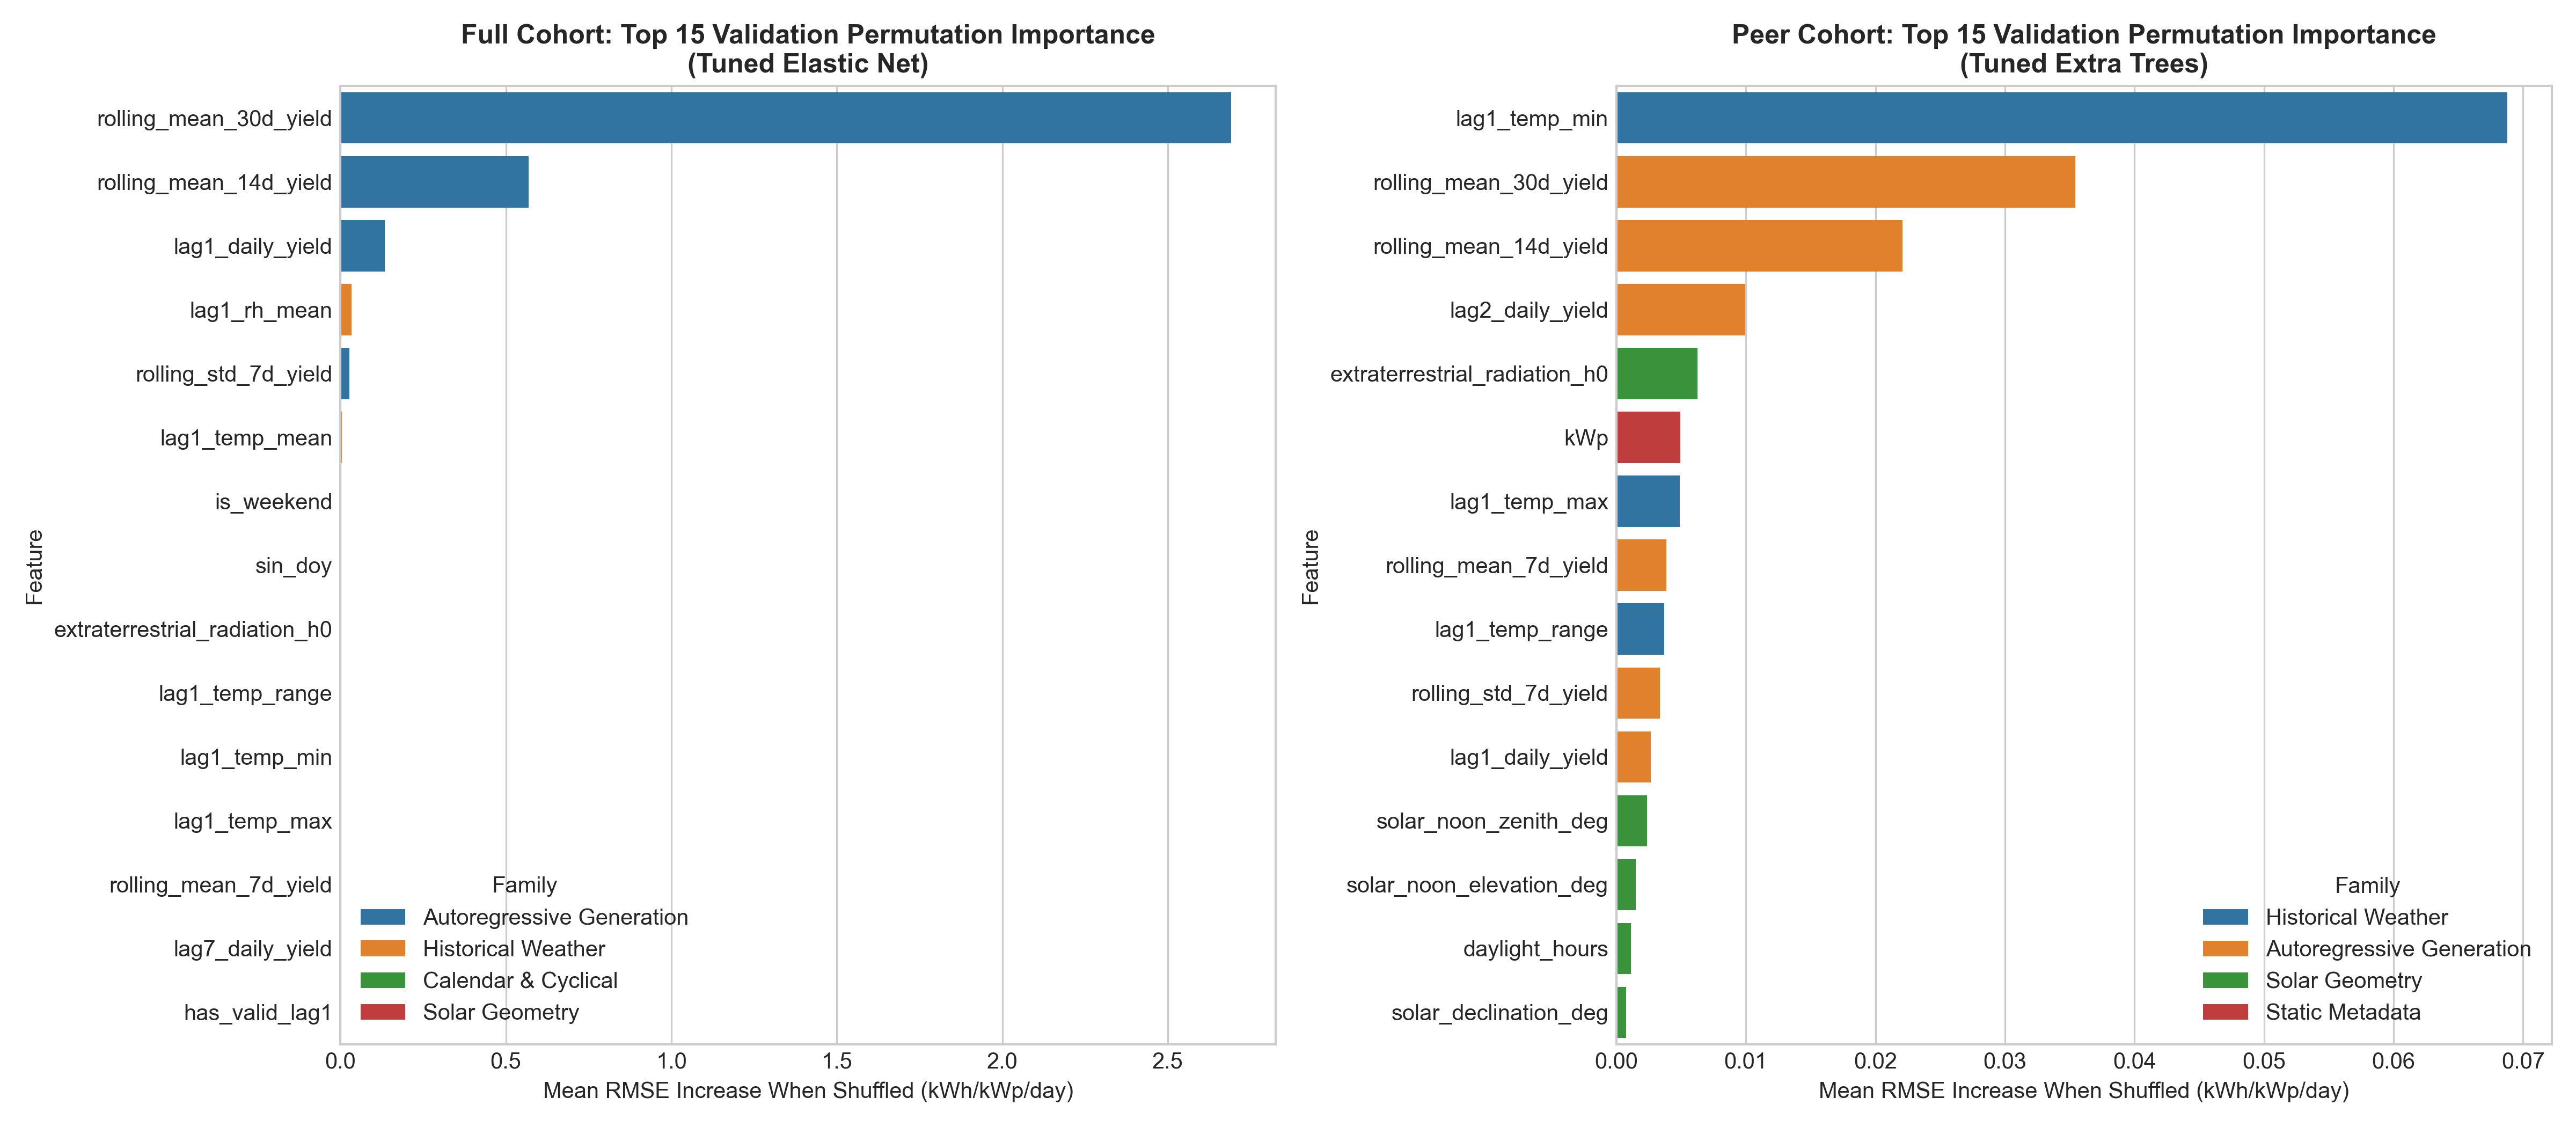

In [8]:
df_importance = pd.read_csv('../../reports/phase4/feature_importance_analysis.csv')
print("=== TOP 10 PERMUTATION IMPORTANCE: FULL COHORT (TUNED ELASTIC NET) ===")
display(df_importance.sort_values(by='Full_Enet_Perm_RMSE_Drop', ascending=False)[['Feature', 'Family', 'Full_Enet_Coef', 'Full_Enet_Perm_RMSE_Drop']].head(10))

print("\n=== TOP 10 PERMUTATION IMPORTANCE: PEER COHORT (TUNED EXTRA TREES) ===")
display(df_importance.sort_values(by='Peer_ET_Perm_RMSE_Drop', ascending=False)[['Feature', 'Family', 'Peer_ET_MDI', 'Peer_ET_Perm_RMSE_Drop']].head(10))

# Display Figure 5
fig5_path = 'figures/permutation_feature_importance.png'
if os.path.exists(fig5_path):
    display(Image(filename=fig5_path))

### 10. Residual Diagnostics, Site-Wise Error & Seasonal Distribution Shift

We conduct diagnostics into:
- Distribution of prediction errors ($e_i = y_i - \hat{y}_i$).
- Error by site across the 24 installations (paying special attention to Site 19 and Site 24).
- The seasonal distribution shift between winter/spring training and summer validation.

--- Figure 6: Site-Wise Error Analysis ---


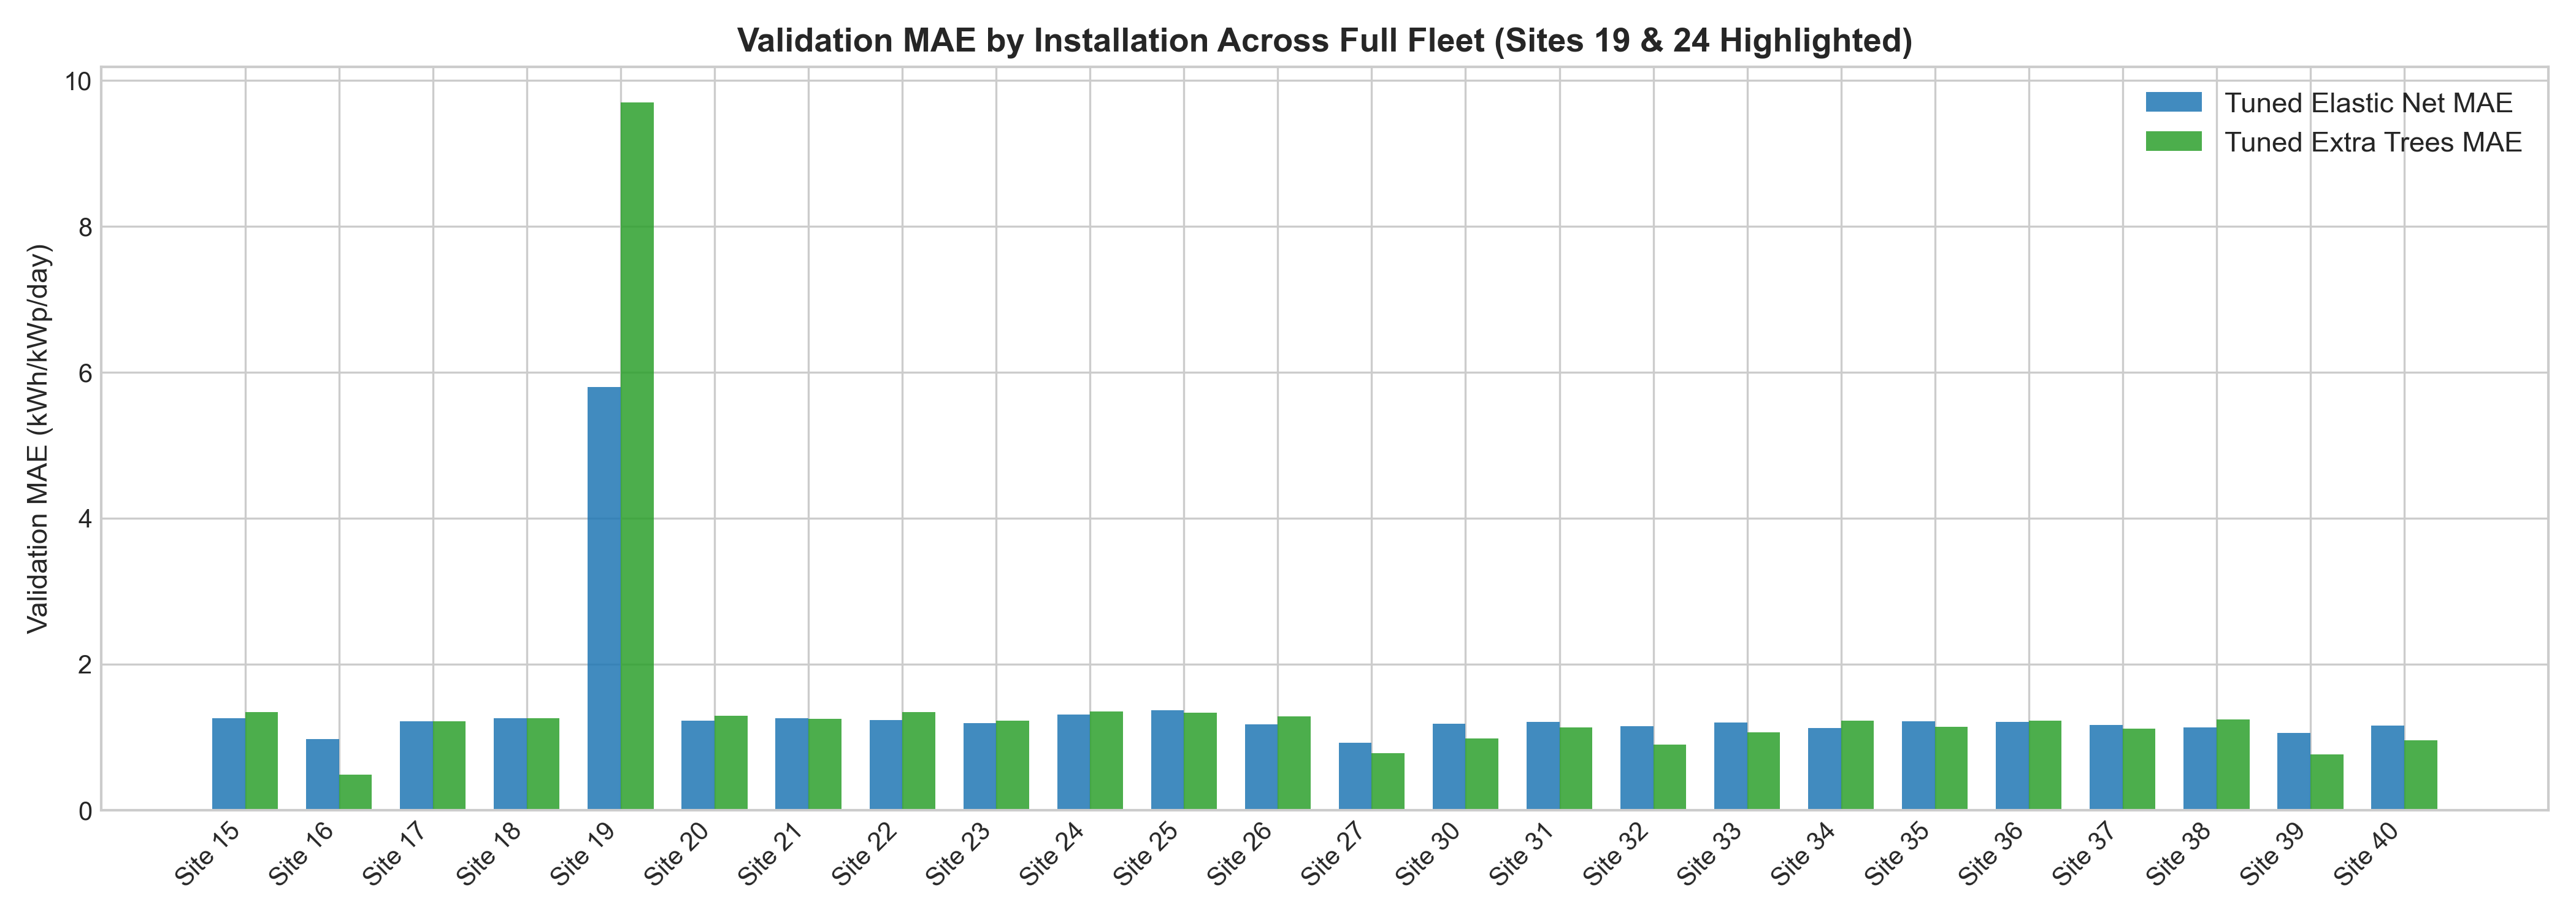

--- Figure 7: Seasonal Distribution Shift & Residuals ---


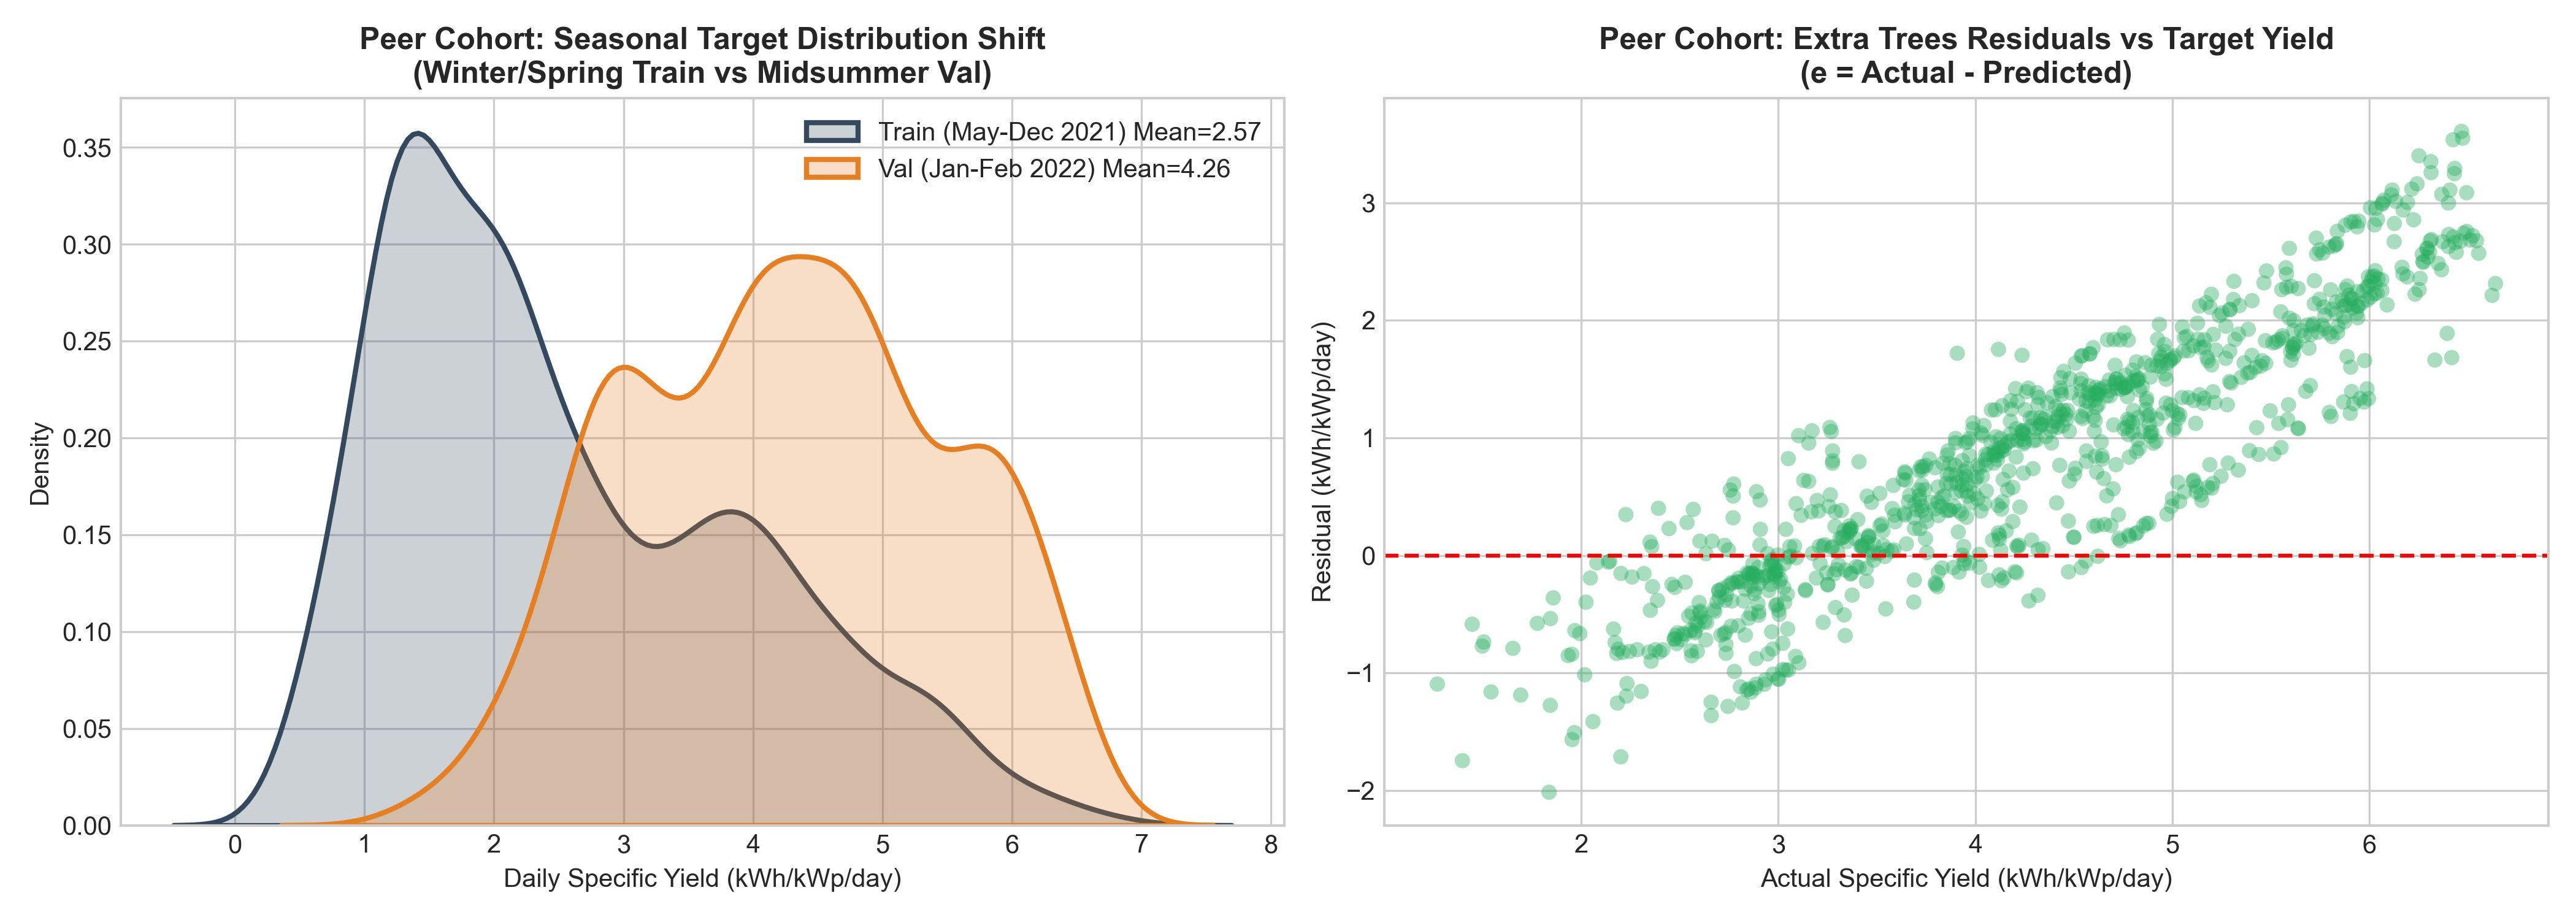

In [9]:
# Display Figure 6: Site-wise Error Diagnostics
fig6_path = 'figures/site_wise_error_analysis.png'
if os.path.exists(fig6_path):
    print("--- Figure 6: Site-Wise Error Analysis ---")
    display(Image(filename=fig6_path))

# Display Figure 7: Seasonal Distribution Shift & Residuals
fig7_path = 'figures/seasonal_distribution_shift_and_residuals.png'
if os.path.exists(fig7_path):
    print("--- Figure 7: Seasonal Distribution Shift & Residuals ---")
    display(Image(filename=fig7_path))

### 11. Multi-Objective Comparison & Operational Feasibility

We benchmark the operational feasibility of leading models across:
1. **Predictive Performance:** MAE, RMSE, $R^2$.
2. **Latency:** Mean inference latency per site-day (measured over 500 repeated trials using `time.perf_counter_ns`).
3. **Artifact Size:** Serialized `.joblib` model footprint on disk.

=== OPERATIONAL & MULTI-OBJECTIVE TRADE-OFF COMPARISON ===


,Cohort,Role,Model,Val_MAE,Val_RMSE,Val_R2,Size (KB),Latency (us/site-day)
0,Full Cohort (24),Primary ML,Tuned Elastic Net,1.3765,2.0134,0.8484,2.7,349.6
1,Full Cohort (24),Fallback ML,Tuned Extra Trees,1.4924,2.7264,0.7220,1884.5,14366.6
2,Full Cohort (24),Reference Benchmark,Persistence Baseline (Lag 1),1.4981,3.1874,0.6207,0.0,0.0
3,Peer Cohort (22),Primary ML,Tuned Extra Trees,1.0793,1.3462,-0.2637,17671.8,14206.0
4,Peer Cohort (22),Fallback ML,Tuned Elastic Net,1.3871,1.6366,-0.8677,2.7,340.5
5,Peer Cohort (22),Reference Benchmark,Persistence Baseline (Lag 1),1.1319,1.4984,-0.5661,0.0,0.0


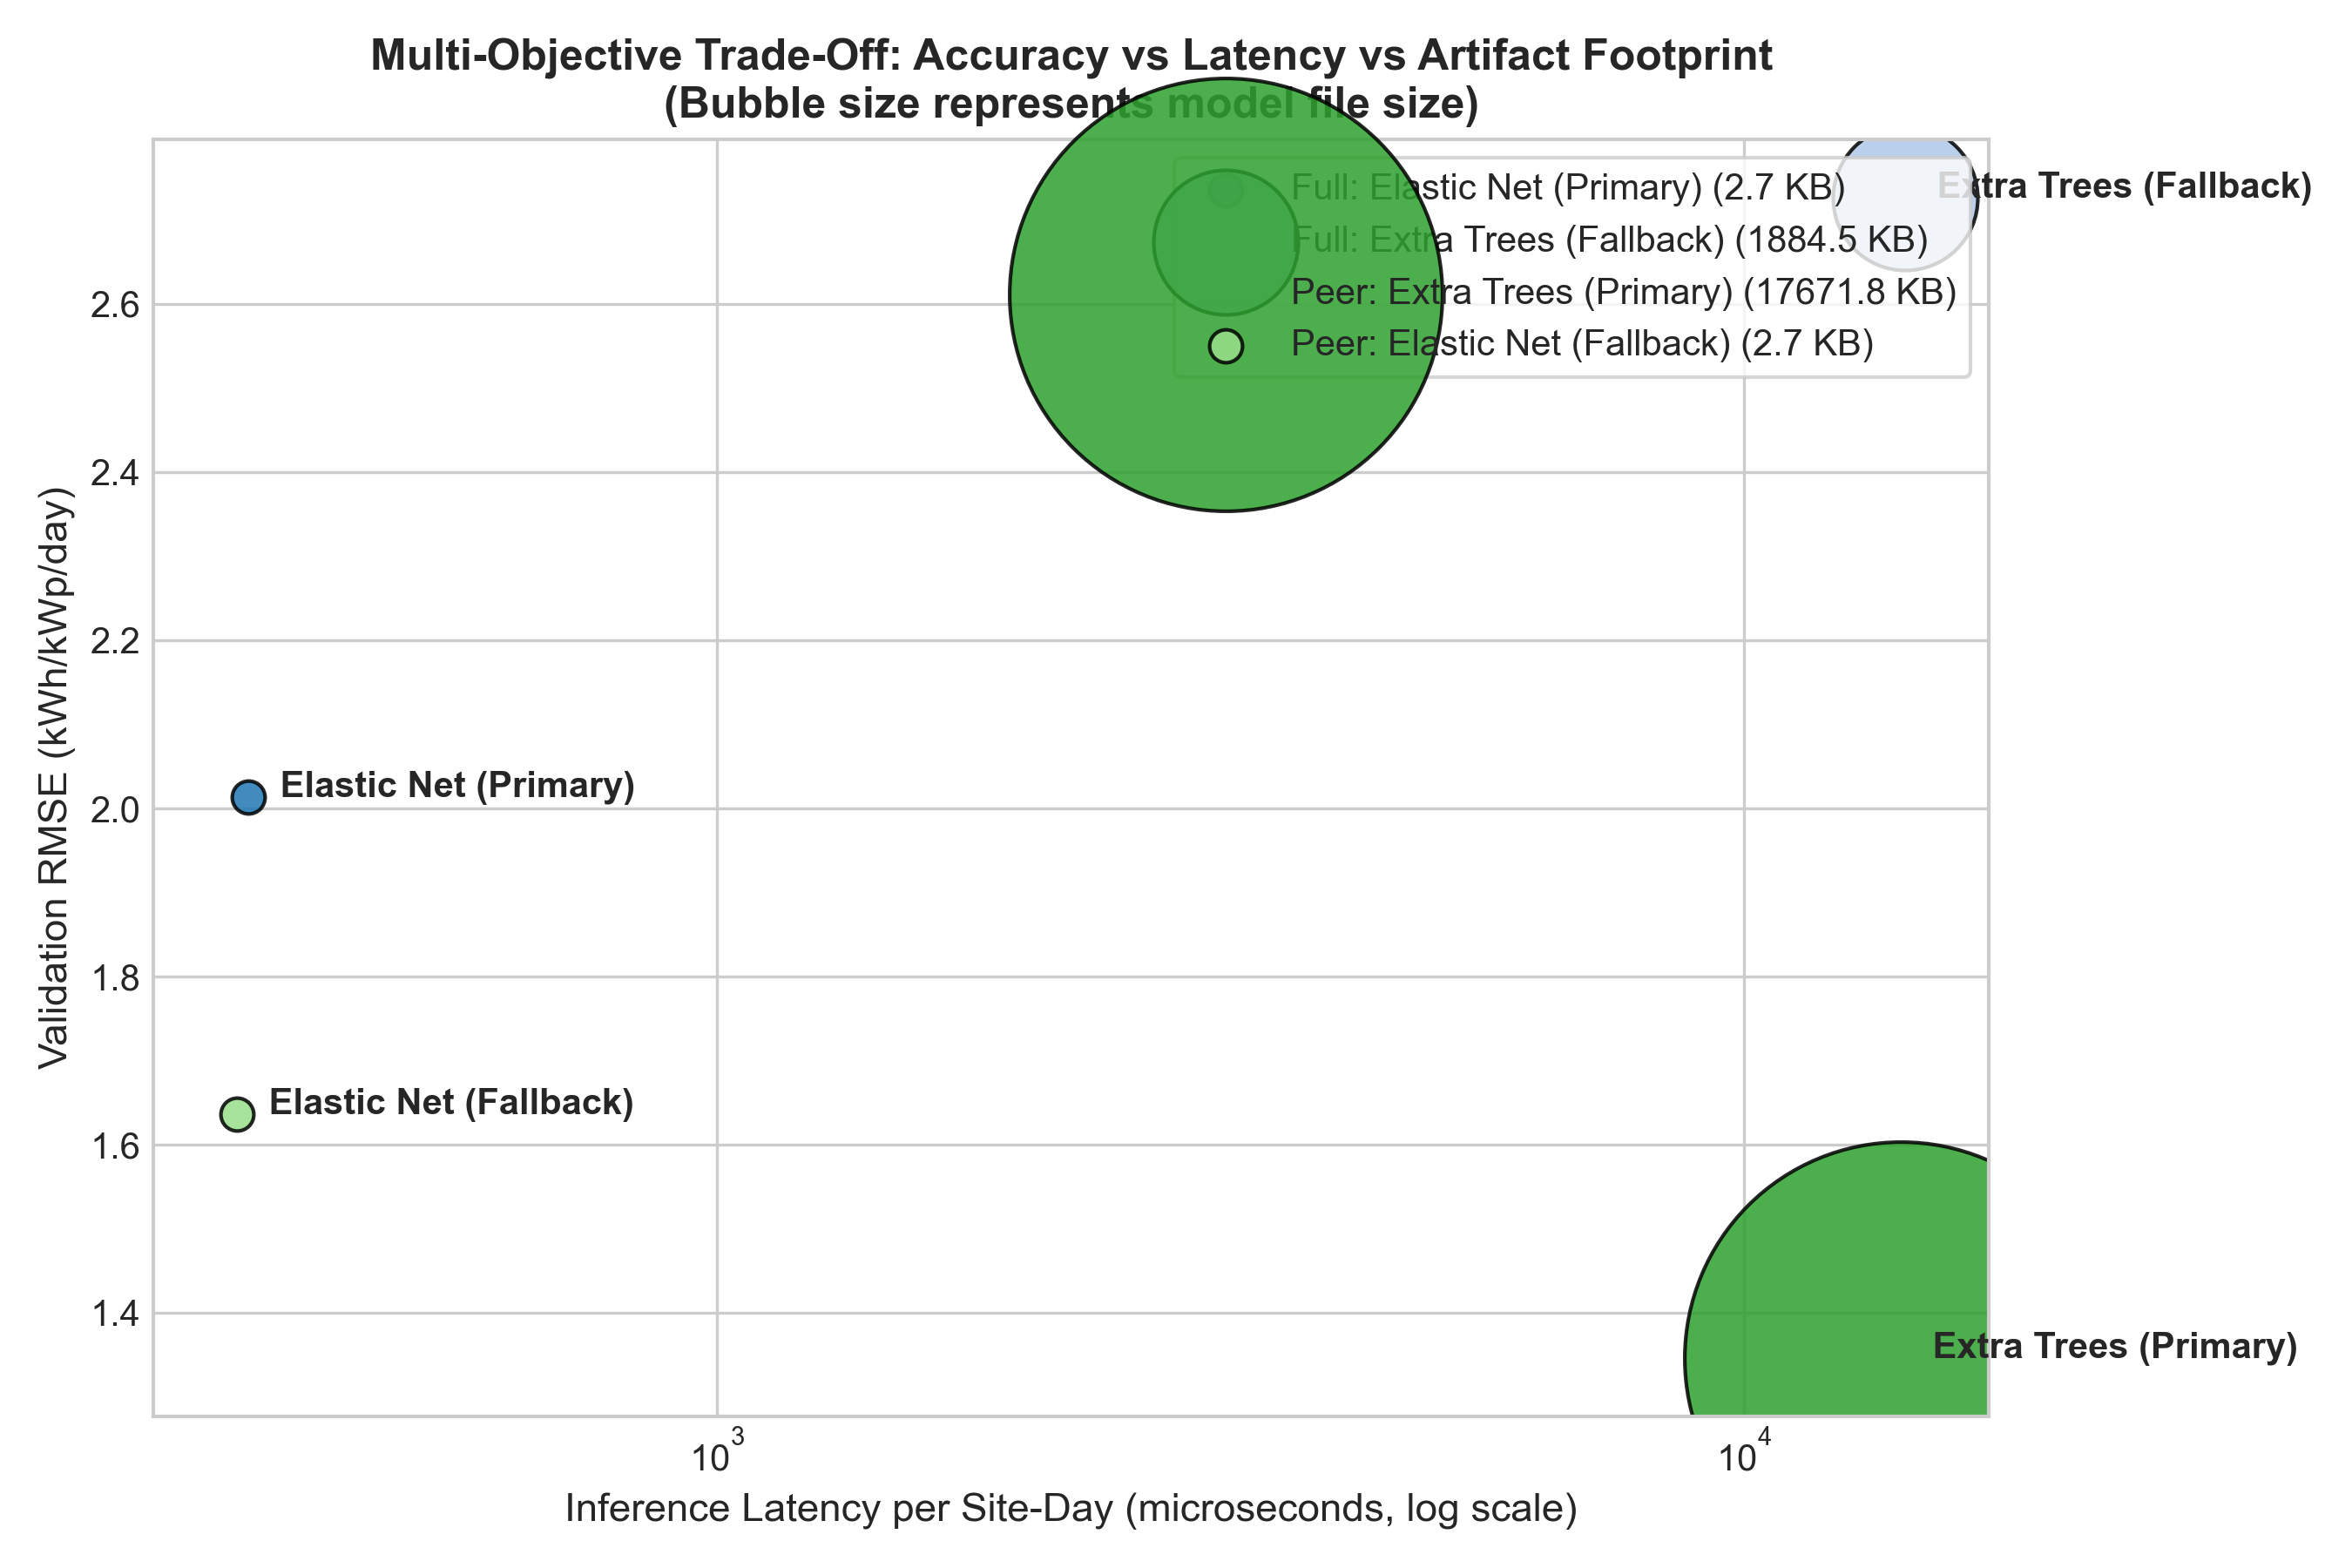

In [10]:
# Load Model Metadata
with open('../../models/phase4/model_metadata.json') as f:
    meta = json.load(f)

print("=== OPERATIONAL & MULTI-OBJECTIVE TRADE-OFF COMPARISON ===")
summary_mo = [
    {
        'Cohort': 'Full Cohort (24)',
        'Role': 'Primary ML',
        'Model': meta['full_cohort_candidates']['primary']['name'],
        'Val_MAE': meta['full_cohort_candidates']['primary']['val_mae'],
        'Val_RMSE': meta['full_cohort_candidates']['primary']['val_rmse'],
        'Val_R2': meta['full_cohort_candidates']['primary']['val_r2'],
        'Size (KB)': meta['full_cohort_candidates']['primary']['size_kb'],
        'Latency (us/site-day)': meta['full_cohort_candidates']['primary']['latency_us']
    },
    {
        'Cohort': 'Full Cohort (24)',
        'Role': 'Fallback ML',
        'Model': meta['full_cohort_candidates']['fallback']['name'],
        'Val_MAE': meta['full_cohort_candidates']['fallback']['val_mae'],
        'Val_RMSE': meta['full_cohort_candidates']['fallback']['val_rmse'],
        'Val_R2': meta['full_cohort_candidates']['fallback']['val_r2'],
        'Size (KB)': meta['full_cohort_candidates']['fallback']['size_kb'],
        'Latency (us/site-day)': meta['full_cohort_candidates']['fallback']['latency_us']
    },
    {
        'Cohort': 'Full Cohort (24)',
        'Role': 'Reference Benchmark',
        'Model': meta['full_cohort_candidates']['reference_benchmark']['name'],
        'Val_MAE': meta['full_cohort_candidates']['reference_benchmark']['val_mae'],
        'Val_RMSE': meta['full_cohort_candidates']['reference_benchmark']['val_rmse'],
        'Val_R2': meta['full_cohort_candidates']['reference_benchmark']['val_r2'],
        'Size (KB)': 0.0,
        'Latency (us/site-day)': 0.0
    },
    {
        'Cohort': 'Peer Cohort (22)',
        'Role': 'Primary ML',
        'Model': meta['peer_cohort_candidates']['primary']['name'],
        'Val_MAE': meta['peer_cohort_candidates']['primary']['val_mae'],
        'Val_RMSE': meta['peer_cohort_candidates']['primary']['val_rmse'],
        'Val_R2': meta['peer_cohort_candidates']['primary']['val_r2'],
        'Size (KB)': meta['peer_cohort_candidates']['primary']['size_kb'],
        'Latency (us/site-day)': meta['peer_cohort_candidates']['primary']['latency_us']
    },
    {
        'Cohort': 'Peer Cohort (22)',
        'Role': 'Fallback ML',
        'Model': meta['peer_cohort_candidates']['fallback']['name'],
        'Val_MAE': meta['peer_cohort_candidates']['fallback']['val_mae'],
        'Val_RMSE': meta['peer_cohort_candidates']['fallback']['val_rmse'],
        'Val_R2': meta['peer_cohort_candidates']['fallback']['val_r2'],
        'Size (KB)': meta['peer_cohort_candidates']['fallback']['size_kb'],
        'Latency (us/site-day)': meta['peer_cohort_candidates']['fallback']['latency_us']
    },
    {
        'Cohort': 'Peer Cohort (22)',
        'Role': 'Reference Benchmark',
        'Model': meta['peer_cohort_candidates']['reference_benchmark']['name'],
        'Val_MAE': meta['peer_cohort_candidates']['reference_benchmark']['val_mae'],
        'Val_RMSE': meta['peer_cohort_candidates']['reference_benchmark']['val_rmse'],
        'Val_R2': meta['peer_cohort_candidates']['reference_benchmark']['val_r2'],
        'Size (KB)': 0.0,
        'Latency (us/site-day)': 0.0
    }
]
display(pd.DataFrame(summary_mo))

# Display Figure 8: Trade-Off Scatter
fig8_path = 'figures/multiobjective_tradeoffs.png'
if os.path.exists(fig8_path):
    display(Image(filename=fig8_path))

### 12. Final Candidate Selection & Phase 5 Handover

#### Candidate Summary:
1. **Dataset A (Full Cohort — 24 Sites):**
   - **Primary ML Candidate:** **Tuned Elastic Net** ($lpha=0.05, l_1=0.9$).
     - *Validation Performance:* $	ext{MAE} = 1.3765$, $	ext{RMSE} = 2.0134$, $R^2 = 0.8484$.
     - *Strengths:* Captures 84.8% of variance across 24 installations including Site 19, ultra-lightweight ($2.7	ext{ KB}$), microsecond inference ($350\ \mu	ext{s}$).
   - **Fallback Candidate:** **Tuned Extra Trees** ($n=50, 	ext{depth}=10, 	ext{leaf}=2$).
     - *Validation Performance:* $	ext{MAE} = 1.4924$, $	ext{RMSE} = 2.7264$, $R^2 = 0.7220$.
   - **Reference Benchmark:** **Persistence Baseline (Lag 1)** ($	ext{MAE} = 1.4981, 	ext{RMSE} = 3.1874, R^2 = 0.6207$).

2. **Dataset B (Peer Cohort — 22 Sites):**
   - **Primary ML Candidate:** **Tuned Extra Trees** ($n=100, 	ext{depth}=12, 	ext{samples\_split}=2, 	ext{max\_features}=0.8$).
     - *Validation Performance:* $	ext{MAE} = 1.0793$, $	ext{RMSE} = 1.3462$, $R^2 = -0.2637$.
     - *Strengths:* Lowest absolute error of any algorithm tested, beats Train Mean baseline RMSE ($2.0716$) by **35.0%**, and outperforms Persistence baseline ($	ext{RMSE} = 1.4984, 	ext{MAE} = 1.1319$).
   - **Fallback Candidate:** **Tuned Elastic Net** ($lpha=0.05, l_1=0.7$).
     - *Validation Performance:* $	ext{MAE} = 1.3871$, $	ext{RMSE} = 1.6366, R^2 = -0.8677$.
   - **Reference Benchmark:** **Persistence Baseline (Lag 1)** ($	ext{MAE} = 1.1319, 	ext{RMSE} = 1.4984, R^2 = -0.5661$).

#### Phase 5 Evaluation Handover:
- The candidate models are persisted with complete metadata in `models/phase4/model_metadata.json`.
- The **Test Partition (March 1, 2022 – April 23, 2022)** remains untouched and will serve as the uncompromised final evaluation dataset in Phase 5.
- **PHASE 4 STATUS: COMPLETED WITH DOCUMENTED LIMITATIONS.**